# Topology-Preserving Autoencoders (TopoAE)

This notebook introduces the concept of topology-preserving autoencoders as proposed in the paper [Topology-Preserving Autoencoders](https://arxiv.org/abs/1906.00722) by Moor et al. (2019). The goal of TopoAE is to learn a low-dimensional representation of data that preserves the topological structure of the original space.

In this notebook, you will implement a TopoAE model and compare its performance to a standard autoencoder on synthetic datasets. You will use persistent homology to quantify and preserve the topological features of the data in the latent space.

### Learning objectives
- Understand the motivation for preserving topology in representation learning.
- Learn how to compute persistent homology and persistence pairings of a point cloud.
- Implement the topological loss used in TopoAE.
- Train and evaluate a TopoAE on synthetic data.


## 0. Imports

In this section, the required Python libraries for this notebook are imported. These include libraries for numerical computation, data loading, visualization, and persistent homology.


In [1]:
!pip install gudhi
!pip install gdown

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch_topological.nn import VietorisRipsComplex, SignatureLoss

import numpy as np
import matplotlib.pyplot as plt
import pickle
import gdown

from scipy.sparse.csgraph import minimum_spanning_tree
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from torchvision import datasets, transforms

from gudhi import RipsComplex

import warnings
warnings.filterwarnings("ignore")

# Check if GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


In [3]:
import torch_topological.nn as ttnn
print(dir(ttnn))


['AlphaComplex', 'CubicalComplex', 'EulerDistance', 'MultiScaleKernel', 'PersistenceInformation', 'SignatureLoss', 'SlicedWassersteinDistance', 'SlicedWassersteinKernel', 'SummaryStatisticLoss', 'VietorisRipsComplex', 'WassersteinDistance', 'WeightedEulerCurve', '__all__', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', 'alpha_complex', 'cubical_complex', 'data', 'distances', 'loss', 'multi_scale_kernel', 'sliced_wasserstein_distance', 'sliced_wasserstein_kernel', 'vietoris_rips_complex', 'weighted_euler_characteristic_transform']


## 1. Dataset

In this section, you will load and visualize a subset of the MNIST dataset. The MNIST dataset contains grayscale images of handwritten digits from 0 to 9. For this experiment, we will only use the samples corresponding to two digits to create a dataset with a simple but non-trivial topology in the pixel space.


In [4]:
url = 'https://drive.google.com/drive/folders/1ZiCQDdxftIFzrkiRaP48IftA42gT28HV?usp=share_link'
gdown.download_folder(url, quiet=False)
with open('pdo_data/pc_pdo_treatment.pkl', 'rb') as handle:
    PCs = pickle.load(handle)
    PCs = [torch.tensor(StandardScaler().fit_transform(PCs[i]), dtype=torch.float) for i in range(len(PCs))]
    keep = []
    for i in range(len(PCs)):
        if(PCs[i].shape[0]>200):
            keep.append(i)
    le = LabelEncoder()
    labels = le.fit_transform(np.load('pdo_data/labels_pdo_treatment.npy'))
    X = [PCs[i] for i in keep]
    X_flat = [x.flatten() for x in X]

    max_len = max(x.shape[0] for x in X_flat)
    X = torch.stack([
        torch.cat([x, torch.zeros(max_len - x.shape[0])]) if x.shape[0] < max_len else x
        for x in X_flat
    ])

    y = [labels[i] for i in keep]
    X = torch.tensor(X, dtype=torch.float).to(device)
    y = torch.tensor(y, dtype=torch.long).to(device)


Retrieving folder contents


Processing file 1v21XcNbRWPJginkaOMjy06QNOeWvduQc labels_pdo_treatment.npy
Processing file 1B4w0EjtSeANdJQzOHofyG-wJtSq3wM8y pc_pdo_treatment.pkl


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1v21XcNbRWPJginkaOMjy06QNOeWvduQc
To: /Users/annasu/Library/CloudStorage/OneDrive-YaleUniversity/Year 4/Classes/CPSC 6440/HW/PS3/pdo_data/labels_pdo_treatment.npy
100%|██████████| 27.0k/27.0k [00:00<00:00, 4.04MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1B4w0EjtSeANdJQzOHofyG-wJtSq3wM8y
From (redirected): https://drive.google.com/uc?id=1B4w0EjtSeANdJQzOHofyG-wJtSq3wM8y&confirm=t&uuid=2bc9a5ca-9dc9-4c6a-933b-8fb143e2bea9
To: /Users/annasu/Library/CloudStorage/OneDrive-YaleUniversity/Year 4/Classes/CPSC 6440/HW/PS3/pdo_data/pc_pdo_treatment.pkl
100%|██████████| 704M/704M [00:19<00:00, 36.7MB/s] 
Download completed


## 2. Baseline Autoencoder

In this section, you will define and train a standard autoencoder on the MNIST subset. The autoencoder learns a low-dimensional latent representation by minimizing the reconstruction error between the input and the reconstructed output. The architecture consists of an encoder, which maps the input to a latent vector, and a decoder, which maps the latent vector back to the input space.

In [5]:
# Define the baseline autoencoder
class Autoencoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, latent_dim=2):
        super(Autoencoder, self).__init__()
        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim)
        )
        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat, z

# Initialize model, loss, optimizer
latent_dim = 2
model_ae = Autoencoder(X.shape[1], 256, latent_dim=latent_dim).to(device)
criterion_recon = nn.MSELoss()
optimizer_ae = optim.Adam(model_ae.parameters(), lr=1e-3)

### Training the baseline autoencoder

Train the baseline autoencoder using mean squared error loss on the reconstruction. The model is trained for a fixed number of epochs. The reconstruction loss is printed periodically.


In [6]:
from torch.utils.data import DataLoader, TensorDataset

# Prepare data loader
dataset = TensorDataset(X, y)
data_loader = DataLoader(dataset, batch_size=32, shuffle=True)

n_epochs = 20

for epoch in range(1, n_epochs+1):
    epoch_loss = 0.0
    for batch_x, _ in data_loader:
        batch_x = batch_x.to(device)

        optimizer_ae.zero_grad()
        x_hat, z = model_ae(batch_x)
        loss = criterion_recon(x_hat, batch_x)
        loss.backward()
        optimizer_ae.step()

        epoch_loss += loss.item() * batch_x.size(0)

    epoch_loss /= len(data_loader.dataset)
    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch [{epoch}/{n_epochs}] - Reconstruction Loss: {epoch_loss:.6f}")


Epoch [1/20] - Reconstruction Loss: 0.228421
Epoch [5/20] - Reconstruction Loss: 0.187933
Epoch [10/20] - Reconstruction Loss: 0.187998
Epoch [15/20] - Reconstruction Loss: 0.187970
Epoch [20/20] - Reconstruction Loss: 0.187969


### Visualizing the latent space

After training, project the MNIST subset into the 2-dimensional latent space learned by the baseline autoencoder and visualize it.


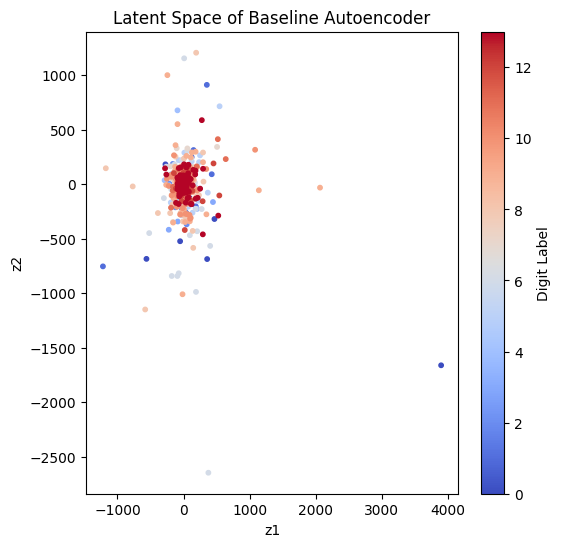

In [7]:
model_ae.eval()
with torch.no_grad():
    Z = model_ae.encoder(X.to(device)).cpu().numpy()
    labels = y.cpu().numpy()

plt.figure(figsize=(6,6))
plt.scatter(Z[:, 0], Z[:, 1], c=labels, cmap='coolwarm', s=10)
plt.title("Latent Space of Baseline Autoencoder")
plt.xlabel("z1")
plt.ylabel("z2")
plt.colorbar(label="Digit Label")
plt.show()

## 3. Topological Autoencoder

In this section, you will implement the topological loss as described in the TopoAE paper.  
The topological loss is computed by comparing the pairwise distances of persistence pairings between the input space and the latent space.  

### Persistent homology
Persistent homology is used to extract the most important topological features from a point cloud.  
For a point cloud \( X \), its 0-dimensional persistence diagram describes the order and scale at which connected components merge as the connectivity threshold increases.

### Loss definition
Let \( \Pi_X \) and \( \Pi_Z \) be the persistence pairings in the input space \( X \) and latent space \( Z \), respectively.  
The topological loss is defined as:

$$
L_t = \frac{1}{2} \| A_X[\Pi_X] - A_Z[\Pi_X] \|^2 + \frac{1}{2} \| A_Z[\Pi_Z] - A_X[\Pi_Z] \|^2
$$

where \( A_X \) and \( A_Z \) are the pairwise distance matrices of \( X \) and \( Z \), and \( \Pi_X \), \( \Pi_Z \) are the indices of persistence pairings computed using Vietoris–Rips complexes.


The TopoAE extends the standard autoencoder by adding the topological loss to the reconstruction loss.  
The total loss is given by:

$$
L = L_\text{reconstruction} + \lambda L_t
$$

where \( L_\text{reconstruction} \) is the mean squared error between the input and its reconstruction, \( L_t \) is the topological loss, and \( \lambda \) is a hyperparameter controlling the weight of the topological term.


In [8]:
class TopoAE(Autoencoder):
    def __init__(self, input_dim, hidden_dim, latent_dim=2, lambda_topo=1.0):
        super().__init__(input_dim, latent_dim)
        self.lambda_topo = lambda_topo
        self.vr = VietorisRipsComplex(dim=1) # compute up to H1, can change for ablation
        self.sig_loss = SignatureLoss(p=2, normalise=True, dimensions=0)

    def compute_loss(self, batch_x):
        x_hat, z = self.forward(batch_x)
        loss_recon = criterion_recon(x_hat, batch_x)

        pi_x = self.vr(batch_x)  # list of PersistenceInformation
        pi_z = self.vr(z)

        loss_topo = self.sig_loss((batch_x, pi_x), (z, pi_z))
        total = loss_recon + self.lambda_topo * loss_topo
        return total, loss_recon.item(), float(loss_topo.detach().cpu())

# Initialize TopoAE
lambda_topo = 0.1 # try [0.0, 0.1, 0.5, 1.0]
model_topoae = TopoAE(X.shape[1], 256, latent_dim=latent_dim, lambda_topo=lambda_topo).to(device)
optimizer_topoae = optim.Adam(model_topoae.parameters(), lr=1e-3)

### Plotting the persistence diagrams for PDO latent embeddings

In [9]:
# Function to retrieve pi_z
def get_pi_z(batch_x):
    with torch.no_grad():
        _, z = model_topoae.forward(batch_x)
        pi_z = model_topoae.vr(z)
    return pi_z

# Plot persistence diagram of pi_z for a batch
batch_x, _ = next(iter(data_loader))
pi_z = get_pi_z(batch_x.to(device))
print(type(pi_z))
print(len(pi_z))
for pi in pi_z:
    print("dim", pi.dimension, "diagram shape", pi.diagram.shape)

<class 'list'>
2
dim 0 diagram shape torch.Size([22, 2])
dim 1 diagram shape torch.Size([1, 2])


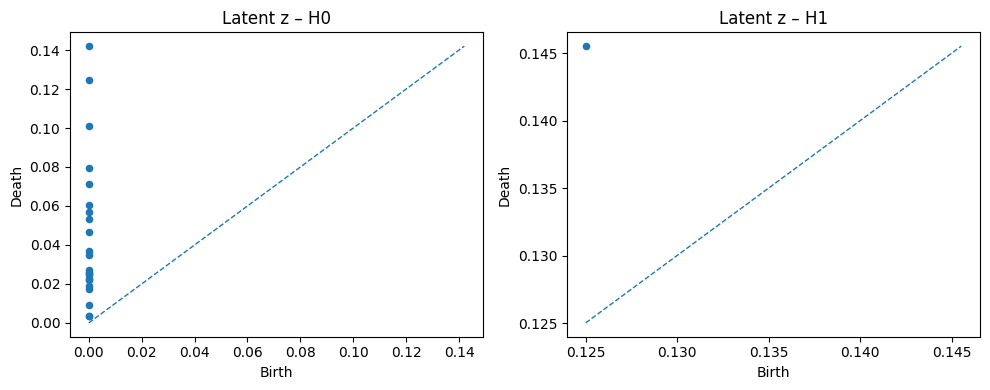

In [10]:
def plot_persistence_diagrams_separate(pi_z, title_prefix="z"):
    # Assume dims 0 and 1, but this will adapt to whatever is in pi_z
    n = len(pi_z)
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 4))

    if n == 1:
        axes = [axes]  # for consistent indexing

    for ax, pi in zip(axes, pi_z):
        dgm = pi.diagram.detach().cpu().numpy()
        dim = int(pi.dimension)

        if dgm.size == 0:
            ax.set_title(f"{title_prefix} – H{dim} (empty)")
            ax.set_xlabel("Birth")
            ax.set_ylabel("Death")
            continue

        ax.scatter(dgm[:, 0], dgm[:, 1], s=20)
        min_bd = dgm.min()
        max_bd = dgm.max()
        ax.plot([min_bd, max_bd], [min_bd, max_bd], linestyle="--", linewidth=1)

        ax.set_title(f"{title_prefix} – H{dim}")
        ax.set_xlabel("Birth")
        ax.set_ylabel("Death")

    plt.tight_layout()
    return fig, axes

# Example call:
fig, axes = plot_persistence_diagrams_separate(pi_z, title_prefix="Latent z")
plt.show()

### Training the TopoAE

Train the TopoAE by minimizing the sum of reconstruction loss and weighted topological loss.  
Both losses are logged during training to monitor their behavior.


In [11]:
n_epochs = 100

for epoch in range(1, n_epochs+1):
    epoch_loss = 0.0
    epoch_recon = 0.0
    epoch_topo = 0.0
    for batch_x, _ in data_loader:
        batch_x = batch_x.to(device)

        optimizer_topoae.zero_grad()
        total_loss, loss_recon, loss_topo = model_topoae.compute_loss(batch_x)
        total_loss.backward()
        optimizer_topoae.step()

        epoch_loss += total_loss.item() * batch_x.size(0)
        epoch_recon += loss_recon * batch_x.size(0)
        epoch_topo += loss_topo * batch_x.size(0)

    epoch_loss /= len(data_loader.dataset)
    epoch_recon /= len(data_loader.dataset)
    epoch_topo /= len(data_loader.dataset)

    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch [{epoch}/{n_epochs}] - Total: {epoch_loss:.6f} | Recon: {epoch_recon:.6f} | Topo: {epoch_topo:.6f}")


Epoch [1/100] - Total: 0.672568 | Recon: 0.441898 | Topo: 2.306699
Epoch [5/100] - Total: 0.555773 | Recon: 0.334990 | Topo: 2.207826
Epoch [10/100] - Total: 0.426214 | Recon: 0.209388 | Topo: 2.168260
Epoch [15/100] - Total: 0.421330 | Recon: 0.195756 | Topo: 2.255733
Epoch [20/100] - Total: 0.401331 | Recon: 0.192046 | Topo: 2.092847
Epoch [25/100] - Total: 0.393437 | Recon: 0.190383 | Topo: 2.030534
Epoch [30/100] - Total: 0.391062 | Recon: 0.189499 | Topo: 2.015639
Epoch [35/100] - Total: 0.385637 | Recon: 0.188929 | Topo: 1.967081
Epoch [40/100] - Total: 0.391886 | Recon: 0.188596 | Topo: 2.032903
Epoch [45/100] - Total: 0.376128 | Recon: 0.188404 | Topo: 1.877242
Epoch [50/100] - Total: 0.375665 | Recon: 0.188258 | Topo: 1.874069
Epoch [55/100] - Total: 0.382489 | Recon: 0.188155 | Topo: 1.943337
Epoch [60/100] - Total: 0.380242 | Recon: 0.188086 | Topo: 1.921560
Epoch [65/100] - Total: 0.377124 | Recon: 0.188036 | Topo: 1.890878
Epoch [70/100] - Total: 0.375722 | Recon: 0.187999

### Visualizing the latent space

After training, project the MNIST subset into the 2-dimensional latent space learned by the TopoAE and visualize it.


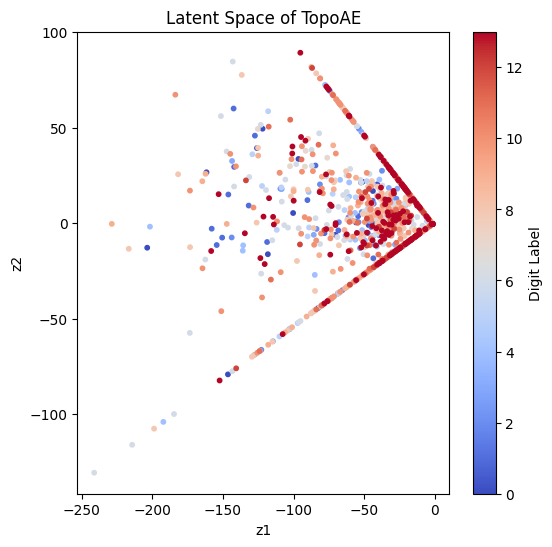

In [12]:
model_topoae.eval()
with torch.no_grad():
    Z_topo = model_topoae.encoder(X.to(device)).cpu().numpy()
    labels = y.cpu().numpy()

plt.figure(figsize=(6,6))
plt.scatter(Z_topo[:, 0], Z_topo[:, 1], c=labels, cmap='coolwarm', s=10)
plt.title("Latent Space of TopoAE")
plt.xlabel("z1")
plt.ylabel("z2")
plt.colorbar(label="Digit Label")
plt.show()


## 4. Evaluation

In this section, you will evaluate the performance of the TopoAE compared to the baseline autoencoder.  
The evaluation is done by computing and visualizing the 0-dimensional persistence diagrams of the latent representations learned by both models.  
Persistence diagrams show the birth and death of connected components in the latent space as the distance threshold increases.


In [13]:
model_topoae.eval()
with torch.no_grad():
    Z_topo = model_topoae.encoder(X.to(device)).cpu().numpy()
    labels = y.cpu().numpy()


In [ ]:

X_embed = Z # change to Z_topo to compare with baseline
y_np = labels

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"acc": "accuracy", "f1_macro": "f1_macro"}

# (A) Logistic Regression (fast, supports probabilities, handles imbalance)
logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000, n_jobs=-1, class_weight="balanced")
)
res_log = cross_validate(logreg, X_embed, y_np, cv=skf, scoring=scoring)

print("LogReg 5-fold CV:")
print(f"  Acc     = {res_log['test_acc'].mean():.4f} ± {res_log['test_acc'].std():.4f}")
print(f"  F1-macro= {res_log['test_f1_macro'].mean():.4f} ± {res_log['test_f1_macro'].std():.4f}")

# (B) Optional: Linear SVM (often strong on small latent dims)
svm_lin = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear", class_weight="balanced")  # set probability=True if you need ROC, slower
)
res_svm = cross_validate(svm_lin, X_embed, y_np, cv=skf, scoring=scoring)

print("\nLinear SVM 5-fold CV:")
print(f"  Acc     = {res_svm['test_acc'].mean():.4f} ± {res_svm['test_acc'].std():.4f}")
print(f"  F1-macro= {res_svm['test_f1_macro'].mean():.4f} ± {res_svm['test_f1_macro'].std():.4f}")


LogReg 5-fold CV:
  Acc     = 0.0585 ± 0.0089
  F1-macro= 0.0491 ± 0.0065

Linear SVM 5-fold CV:
  Acc     = 0.0695 ± 0.0165
  F1-macro= 0.0398 ± 0.0151
